# AI651 Assignment 1 — Task 2: Autoformer Leaderboard

This notebook is a clean Task 2 baseline.

It:
- loads `student_train.csv` and `student_test.csv`
- creates a chronological validation split
- builds an Autoformer-style model with **series decomposition** and **time-delay auto-correlation**
- evaluates RMSE, MAE, and sMAPE
- runs multiple random seeds
- refits on the complete training series
- generates exactly **168** predictions and a leaderboard-ready comma-separated string

### Files expected beside this notebook
- `student_train.csv`
- `student_test.csv`

The optional external-data ablation is intentionally left for a follow-up experiment after establishing the target-only baseline.

In [66]:
import math
import time
import random
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

PyTorch: 2.14.0+cu130
Device: cuda


In [67]:
TRAIN_PATH = "Data/student_train.csv"
TEST_PATH = "Data/student_test.csv"

PRED_LEN = 168
CONTEXT_LEN = 336
D_MODEL = 16
HEADS = 4
LAYERS = 2
KERNEL = 25
DROPOUT = 0.1

BATCH_SIZE = 64
LR = 3e-4
EPOCHS = 30
WEIGHT_DECAY = 1e-4

SEEDS = [42, 123, 456]

# Five non-overlapping 168-step validation blocks from the end.
VAL_BLOCKS = 5

print("Context length:", CONTEXT_LEN)
print("Forecast horizon:", PRED_LEN)

Context length: 336
Forecast horizon: 168


In [68]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

## Load and inspect data

In [69]:
df = pd.read_csv(TRAIN_PATH)

display(df.head())
display(df.tail())

assert "time_idx" in df.columns
assert "value" in df.columns

values = df["value"].to_numpy(dtype=np.float32)

print("Shape:", df.shape)
print("Observations:", len(values))
print("Missing target values:", df["value"].isna().sum())
print("Min:", values.min())
print("Max:", values.max())
print("Mean:", values.mean())
print("Std:", values.std())

,time_idx,value
0,1,129
1,2,129
2,3,129
3,4,129
4,5,129


,time_idx,value
43651,43652,20
43652,43653,23
43653,43654,16
43654,43655,17
43655,43656,18


Shape: (43656, 2)
Observations: 43656
Missing target values: 0
Min: 0.0
Max: 994.0
Mean: 98.17354
Std: 90.83372


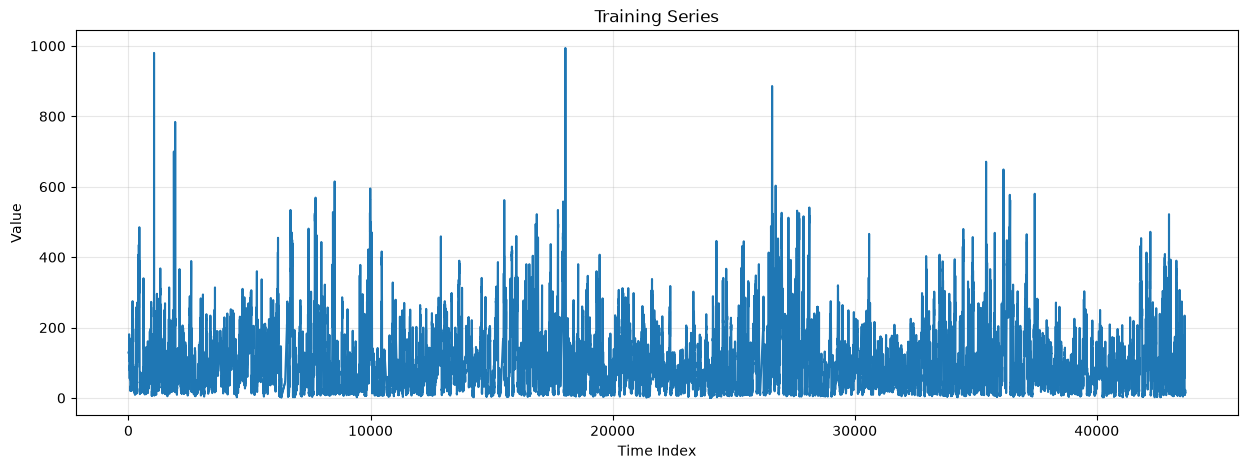

In [70]:
plt.figure(figsize=(15, 5))
plt.plot(df["time_idx"], df["value"])
plt.xlabel("Time Index")
plt.ylabel("Value")
plt.title("Training Series")
plt.grid(alpha=0.3)
plt.show()

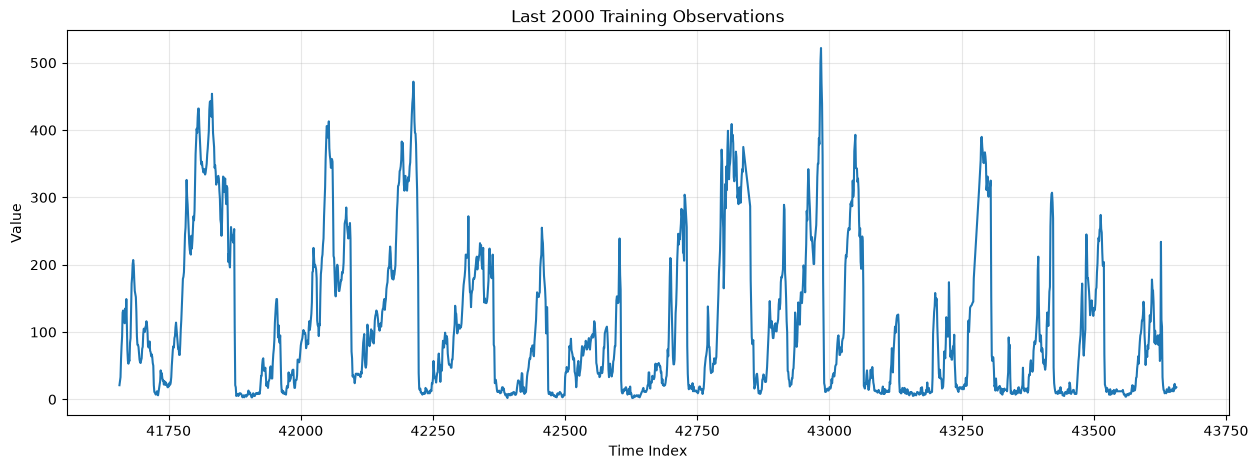

In [71]:
n = min(2000, len(df))

plt.figure(figsize=(15, 5))
plt.plot(df["time_idx"].values[-n:], df["value"].values[-n:])
plt.xlabel("Time Index")
plt.ylabel("Value")
plt.title(f"Last {n} Training Observations")
plt.grid(alpha=0.3)
plt.show()

## Chronological validation and normalization

In [72]:
VAL_SIZE = PRED_LEN * VAL_BLOCKS

train_values = values[:-VAL_SIZE]
val_values = values[-VAL_SIZE:]

TRAIN_MEAN = float(train_values.mean())
TRAIN_STD = float(train_values.std())

if TRAIN_STD == 0:
    raise ValueError("Training standard deviation is zero.")

train_scaled = ((train_values - TRAIN_MEAN) / TRAIN_STD).astype(np.float32)
all_scaled = ((values - TRAIN_MEAN) / TRAIN_STD).astype(np.float32)

print("Training observations:", len(train_values))
print("Validation observations:", len(val_values))
print("Training mean:", TRAIN_MEAN)
print("Training std:", TRAIN_STD)

Training observations: 42816
Validation observations: 840
Training mean: 98.1524429321289
Training std: 90.42195129394531


## Window datasets

In [73]:
class ForecastDataset(Dataset):
    def __init__(self, series, context_len, pred_len, stride=1):
        self.series = torch.as_tensor(series, dtype=torch.float32)
        self.context_len = context_len
        self.pred_len = pred_len

        last_target_start = len(series) - pred_len
        self.target_starts = list(
            range(context_len, last_target_start + 1, stride)
        )

    def __len__(self):
        return len(self.target_starts)

    def __getitem__(self, idx):
        target_start = self.target_starts[idx]

        x = self.series[
            target_start - self.context_len : target_start
        ]
        y = self.series[
            target_start : target_start + self.pred_len
        ]

        return x.unsqueeze(-1), y


class FixedForecastDataset(Dataset):
    def __init__(self, series, target_starts, context_len, pred_len):
        self.series = torch.as_tensor(series, dtype=torch.float32)
        self.target_starts = list(target_starts)
        self.context_len = context_len
        self.pred_len = pred_len

    def __len__(self):
        return len(self.target_starts)

    def __getitem__(self, idx):
        target_start = self.target_starts[idx]

        x = self.series[
            target_start - self.context_len : target_start
        ]
        y = self.series[
            target_start : target_start + self.pred_len
        ]

        return x.unsqueeze(-1), y

In [74]:
train_dataset = ForecastDataset(
    train_scaled,
    context_len=CONTEXT_LEN,
    pred_len=PRED_LEN,
    stride=4,
)

validation_target_starts = [
    len(train_values) + i * PRED_LEN
    for i in range(VAL_BLOCKS)
]

val_dataset = FixedForecastDataset(
    all_scaled,
    target_starts=validation_target_starts,
    context_len=CONTEXT_LEN,
    pred_len=PRED_LEN,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
)

xb, yb = next(iter(train_loader))

print("Training windows:", len(train_dataset))
print("Validation windows:", len(val_dataset))
print("Batch X:", xb.shape)
print("Batch Y:", yb.shape)

Training windows: 10579
Validation windows: 5
Batch X: torch.Size([64, 336, 1])
Batch Y: torch.Size([64, 168])


## Series decomposition

In [75]:
class SeriesDecomposition(nn.Module):
    def __init__(self, kernel):
        super().__init__()

        if kernel < 1 or kernel % 2 == 0:
            raise ValueError("kernel must be positive and odd")

        self.kernel = kernel

    def forward(self, x):
        # x: [B, L, C]
        pad = self.kernel // 2

        x_t = x.transpose(1, 2)
        padded = F.pad(x_t, (pad, pad), mode="replicate")

        trend = F.avg_pool1d(
            padded,
            kernel_size=self.kernel,
            stride=1,
        ).transpose(1, 2)

        remainder = x - trend
        return remainder, trend

In [76]:
test_x = torch.randn(4, CONTEXT_LEN, 1)
seasonal, trend = SeriesDecomposition(KERNEL)(test_x)

reconstruction_error = (
    test_x - (seasonal + trend)
).abs().max().item()

print("Seasonal:", seasonal.shape)
print("Trend:", trend.shape)
print("Max reconstruction error:", reconstruction_error)

assert reconstruction_error < 1e-5

Seasonal: torch.Size([4, 336, 1])
Trend: torch.Size([4, 336, 1])
Max reconstruction error: 1.1920928955078125e-07


## Time-delay auto-correlation

In [77]:
def delay_scores(queries, keys):
    # queries/keys: [B, heads, head_dim, L]
    queries = queries - queries.mean(dim=-1, keepdim=True)
    keys = keys - keys.mean(dim=-1, keepdim=True)

    q_fft = torch.fft.rfft(queries, dim=-1)
    k_fft = torch.fft.rfft(keys, dim=-1)

    correlation = torch.fft.irfft(
        q_fft * k_fft.conj(),
        n=queries.shape[-1],
        dim=-1,
    )

    # One score per delay and example.
    return correlation.mean(dim=(1, 2))


def aggregate_delays(values, delays, weights):
    # values:  [B, heads, head_dim, L]
    # delays:  [B, K]
    # weights: [B, K]

    B, H, D, L = values.shape
    K = delays.shape[1]

    positions = torch.arange(L, device=values.device)

    indices = (
        positions.view(1, 1, L) - delays.unsqueeze(-1)
    ) % L

    expanded_values = values.unsqueeze(1).expand(B, K, H, D, L)

    gather_indices = indices[:, :, None, None, :].expand(
        B, K, H, D, L
    )

    shifted = torch.gather(
        expanded_values,
        dim=-1,
        index=gather_indices,
    )

    weighted = shifted * weights[:, :, None, None, None]

    return weighted.sum(dim=1)

In [78]:
values_test = torch.tensor(
    [10., 20., 30., 40.]
).reshape(1, 1, 1, 4)

delays_test = torch.tensor([[1, 3]])
weights_test = torch.tensor([[0.75, 0.25]])

result = aggregate_delays(
    values_test,
    delays_test,
    weights_test,
)

expected = torch.tensor([35., 15., 25., 25.])

print("Result:", result.flatten())
print("Expected:", expected)

assert torch.allclose(result.flatten(), expected)
print("Delay aggregation test passed.")

Result: tensor([35., 15., 25., 25.])
Expected: tensor([35., 15., 25., 25.])
Delay aggregation test passed.


## Delay mixer

In [79]:
class DelayMixer(nn.Module):
    def __init__(self, d, heads, top_k_factor=2.0):
        super().__init__()

        if d % heads != 0:
            raise ValueError("d must be divisible by heads")

        self.heads = heads
        self.top_k_factor = top_k_factor

        self.query = nn.Linear(d, d)
        self.key = nn.Linear(d, d)
        self.value = nn.Linear(d, d)
        self.out = nn.Linear(d, d)

        self.raw_temperature = nn.Parameter(
            torch.tensor(0.5413248546)
        )

    @property
    def temperature(self):
        return F.softplus(self.raw_temperature) + 1e-6

    def forward(self, x):
        B, L, D = x.shape
        head_dim = D // self.heads

        q = self.query(x).view(
            B, L, self.heads, head_dim
        ).permute(0, 2, 3, 1)

        k = self.key(x).view(
            B, L, self.heads, head_dim
        ).permute(0, 2, 3, 1)

        v = self.value(x).view(
            B, L, self.heads, head_dim
        ).permute(0, 2, 3, 1)

        scores = delay_scores(q, k)

        # Zero delay is trivial; do not select it.
        scores = scores.clone()
        scores[:, 0] = -torch.inf

        top_k = min(
            max(1, math.ceil(self.top_k_factor * math.log(L))),
            L - 1,
        )

        selected_scores, delays = torch.topk(
            scores,
            k=top_k,
            dim=-1,
        )

        weights = F.softmax(
            selected_scores / self.temperature,
            dim=-1,
        )

        mixed = aggregate_delays(
            v,
            delays,
            weights,
        )

        mixed = mixed.permute(
            0, 3, 1, 2
        ).reshape(B, L, D)

        return self.out(mixed)

## Autoformer block and forecasting model

In [80]:
class AutoformerBlock(nn.Module):
    def __init__(self, d, heads, kernel, dropout):
        super().__init__()

        self.mixer = DelayMixer(d, heads)

        self.norm1 = nn.LayerNorm(d)
        self.norm2 = nn.LayerNorm(d)

        self.ffn = nn.Sequential(
            nn.Linear(d, 2 * d),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(2 * d, d),
        )

        self.dropout = nn.Dropout(dropout)

        self.decomp1 = SeriesDecomposition(kernel)
        self.decomp2 = SeriesDecomposition(kernel)

    def forward(self, x):
        x, _ = self.decomp1(
            x + self.dropout(
                self.mixer(self.norm1(x))
            )
        )

        x, _ = self.decomp2(
            x + self.dropout(
                self.ffn(self.norm2(x))
            )
        )

        return x


class Task2Autoformer(nn.Module):
    def __init__(
        self,
        context_len,
        pred_len,
        d=32,
        heads=4,
        layers=2,
        kernel=25,
        dropout=0.1,
    ):
        super().__init__()

        self.context_len = context_len
        self.pred_len = pred_len

        self.decomposition = SeriesDecomposition(kernel)

        self.trend_head = nn.Linear(
            context_len,
            pred_len,
        )

        self.embedding = nn.Conv1d(
            1,
            d,
            kernel_size=3,
            padding=1,
            padding_mode="circular",
            bias=False,
        )

        self.position = nn.Parameter(
            torch.randn(1, context_len, d) * 0.02
        )

        self.blocks = nn.ModuleList([
            AutoformerBlock(
                d=d,
                heads=heads,
                kernel=kernel,
                dropout=dropout,
            )
            for _ in range(layers)
        ])

        self.norm = nn.LayerNorm(d)

        self.channel_head = nn.Linear(d, 1)

        # Then forecast over time: [B, L] -> [B, pred_len]
        self.forecast_head = nn.Linear(
            context_len,
            pred_len,
        )

    def forward(self, x):
        seasonal, trend = self.decomposition(x)

        encoded = self.embedding(
            seasonal.transpose(1, 2)
        ).transpose(1, 2)

        encoded = encoded + self.position

        for block in self.blocks:
            encoded = block(encoded)

        encoded = self.norm(encoded)

        # [B, L, d] -> [B, L, 1] -> [B, L]
        encoded = self.channel_head(encoded).squeeze(-1)

        # [B, L] -> [B, pred_len]
        seasonal_forecast = self.forecast_head(encoded)

        trend_forecast = self.trend_head(
            trend.squeeze(-1)
        )

        return seasonal_forecast + trend_forecast

In [81]:
model = Task2Autoformer(
    context_len=CONTEXT_LEN,
    pred_len=PRED_LEN,
    d=D_MODEL,
    heads=HEADS,
    layers=LAYERS,
    kernel=KERNEL,
    dropout=DROPOUT,
).to(DEVICE)

dummy = torch.randn(
    2, CONTEXT_LEN, 1,
    device=DEVICE,
)

with torch.no_grad():
    output = model(dummy)

PARAMS = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Input:", dummy.shape)
print("Output:", output.shape)
print(f"Trainable parameters: {PARAMS:,}")

assert output.shape == (2, PRED_LEN)

Input: torch.Size([2, 336, 1])
Output: torch.Size([2, 168])
Trainable parameters: 123,155


## Metrics and evaluation

In [82]:
def calculate_metrics(predictions, targets):
    predictions = np.asarray(predictions)
    targets = np.asarray(targets)

    mse = np.mean((predictions - targets) ** 2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(predictions - targets))

    denominator = (
        np.abs(predictions)
        + np.abs(targets)
        + 1e-8
    )

    smape = 100 * np.mean(
        2 * np.abs(predictions - targets)
        / denominator
    )

    return {
        "MSE": float(mse),
        "RMSE": float(rmse),
        "MAE": float(mae),
        "sMAPE": float(smape),
    }


@torch.no_grad()
def evaluate(model, loader, mean, std):
    model.eval()

    predictions = []
    targets = []

    for x, y in loader:
        x = x.to(DEVICE)

        pred = model(x).cpu().numpy()
        y = y.numpy()

        pred = pred * std + mean
        y = y * std + mean

        predictions.append(pred)
        targets.append(y)

    predictions = np.concatenate(predictions, axis=0)
    targets = np.concatenate(targets, axis=0)

    metrics = calculate_metrics(
        predictions,
        targets,
    )

    return metrics, predictions, targets

## Training

In [83]:
def make_model():
    return Task2Autoformer(
        context_len=CONTEXT_LEN,
        pred_len=PRED_LEN,
        d=D_MODEL,
        heads=HEADS,
        layers=LAYERS,
        kernel=KERNEL,
        dropout=DROPOUT,
    ).to(DEVICE)


def train_model(seed, epochs=EPOCHS):
    set_seed(seed)

    model = make_model()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LR,
        weight_decay=WEIGHT_DECAY,
    )

    criterion = nn.MSELoss()

    best_rmse = float("inf")
    best_state = None
    best_epoch = 0

    history = []

    start = time.time()

    for epoch in range(1, epochs + 1):
        model.train()

        running_loss = 0.0
        batches = 0

        for x, y in train_loader:
            x = x.to(DEVICE)
            y = y.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)

            pred = model(x)
            loss = criterion(pred, y)

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0,
            )

            optimizer.step()

            running_loss += loss.item()
            batches += 1

        train_loss = running_loss / max(batches, 1)

        metrics, _, _ = evaluate(
            model,
            val_loader,
            TRAIN_MEAN,
            TRAIN_STD,
        )

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            **metrics,
        })

        print(
            f"Seed {seed} | "
            f"Epoch {epoch:02d} | "
            f"Loss {train_loss:.5f} | "
            f"RMSE {metrics['RMSE']:.4f} | "
            f"MAE {metrics['MAE']:.4f} | "
            f"sMAPE {metrics['sMAPE']:.2f}%"
        )

        if metrics["RMSE"] < best_rmse:
            best_rmse = metrics["RMSE"]
            best_epoch = epoch
            best_state = copy.deepcopy(
                model.state_dict()
            )

    model.load_state_dict(best_state)

    elapsed = time.time() - start

    print()
    print("Best epoch:", best_epoch)
    print("Best validation RMSE:", best_rmse)
    print("Training time:", round(elapsed, 2), "seconds")

    return model, pd.DataFrame(history), best_epoch

## Smoke run

Run this first. If everything works, continue to the multi-seed cell.

In [84]:
model_42, history_42, epoch_42 = train_model(
    seed=42,
    epochs=EPOCHS,
)

Seed 42 | Epoch 01 | Loss 1.00032 | RMSE 107.8442 | MAE 90.0201 | sMAPE 99.08%
Seed 42 | Epoch 02 | Loss 0.94790 | RMSE 105.7773 | MAE 86.7620 | sMAPE 96.83%
Seed 42 | Epoch 03 | Loss 0.92812 | RMSE 108.1263 | MAE 88.6552 | sMAPE 97.28%
Seed 42 | Epoch 04 | Loss 0.91356 | RMSE 106.4052 | MAE 85.0996 | sMAPE 94.67%
Seed 42 | Epoch 05 | Loss 0.90659 | RMSE 105.7402 | MAE 82.7499 | sMAPE 92.57%
Seed 42 | Epoch 06 | Loss 0.90103 | RMSE 106.6205 | MAE 83.8420 | sMAPE 91.94%
Seed 42 | Epoch 07 | Loss 0.89528 | RMSE 108.9656 | MAE 85.0365 | sMAPE 93.16%
Seed 42 | Epoch 08 | Loss 0.89326 | RMSE 106.7104 | MAE 83.1111 | sMAPE 91.83%
Seed 42 | Epoch 09 | Loss 0.88965 | RMSE 108.5172 | MAE 84.1549 | sMAPE 92.88%
Seed 42 | Epoch 10 | Loss 0.88463 | RMSE 107.2262 | MAE 84.0703 | sMAPE 93.71%
Seed 42 | Epoch 11 | Loss 0.88349 | RMSE 107.2816 | MAE 83.7904 | sMAPE 91.77%
Seed 42 | Epoch 12 | Loss 0.87756 | RMSE 110.2727 | MAE 86.6501 | sMAPE 93.10%
Seed 42 | Epoch 13 | Loss 0.87249 | RMSE 111.7637 | 

{'MSE': 11181.0, 'RMSE': 105.74024963378906, 'MAE': 82.74987030029297, 'sMAPE': 92.56565856933594}


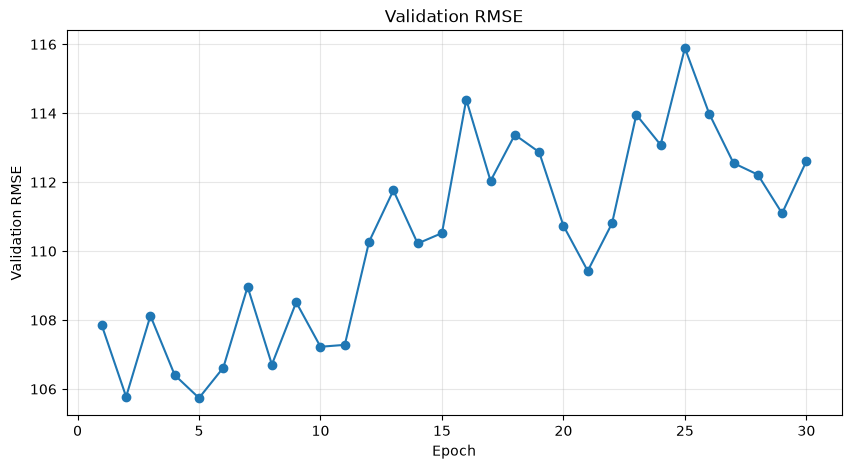

In [85]:
metrics_42, pred_42, target_42 = evaluate(
    model_42,
    val_loader,
    TRAIN_MEAN,
    TRAIN_STD,
)

print(metrics_42)

plt.figure(figsize=(10, 5))
plt.plot(
    history_42["epoch"],
    history_42["RMSE"],
    marker="o",
)
plt.xlabel("Epoch")
plt.ylabel("Validation RMSE")
plt.title("Validation RMSE")
plt.grid(alpha=0.3)
plt.show()

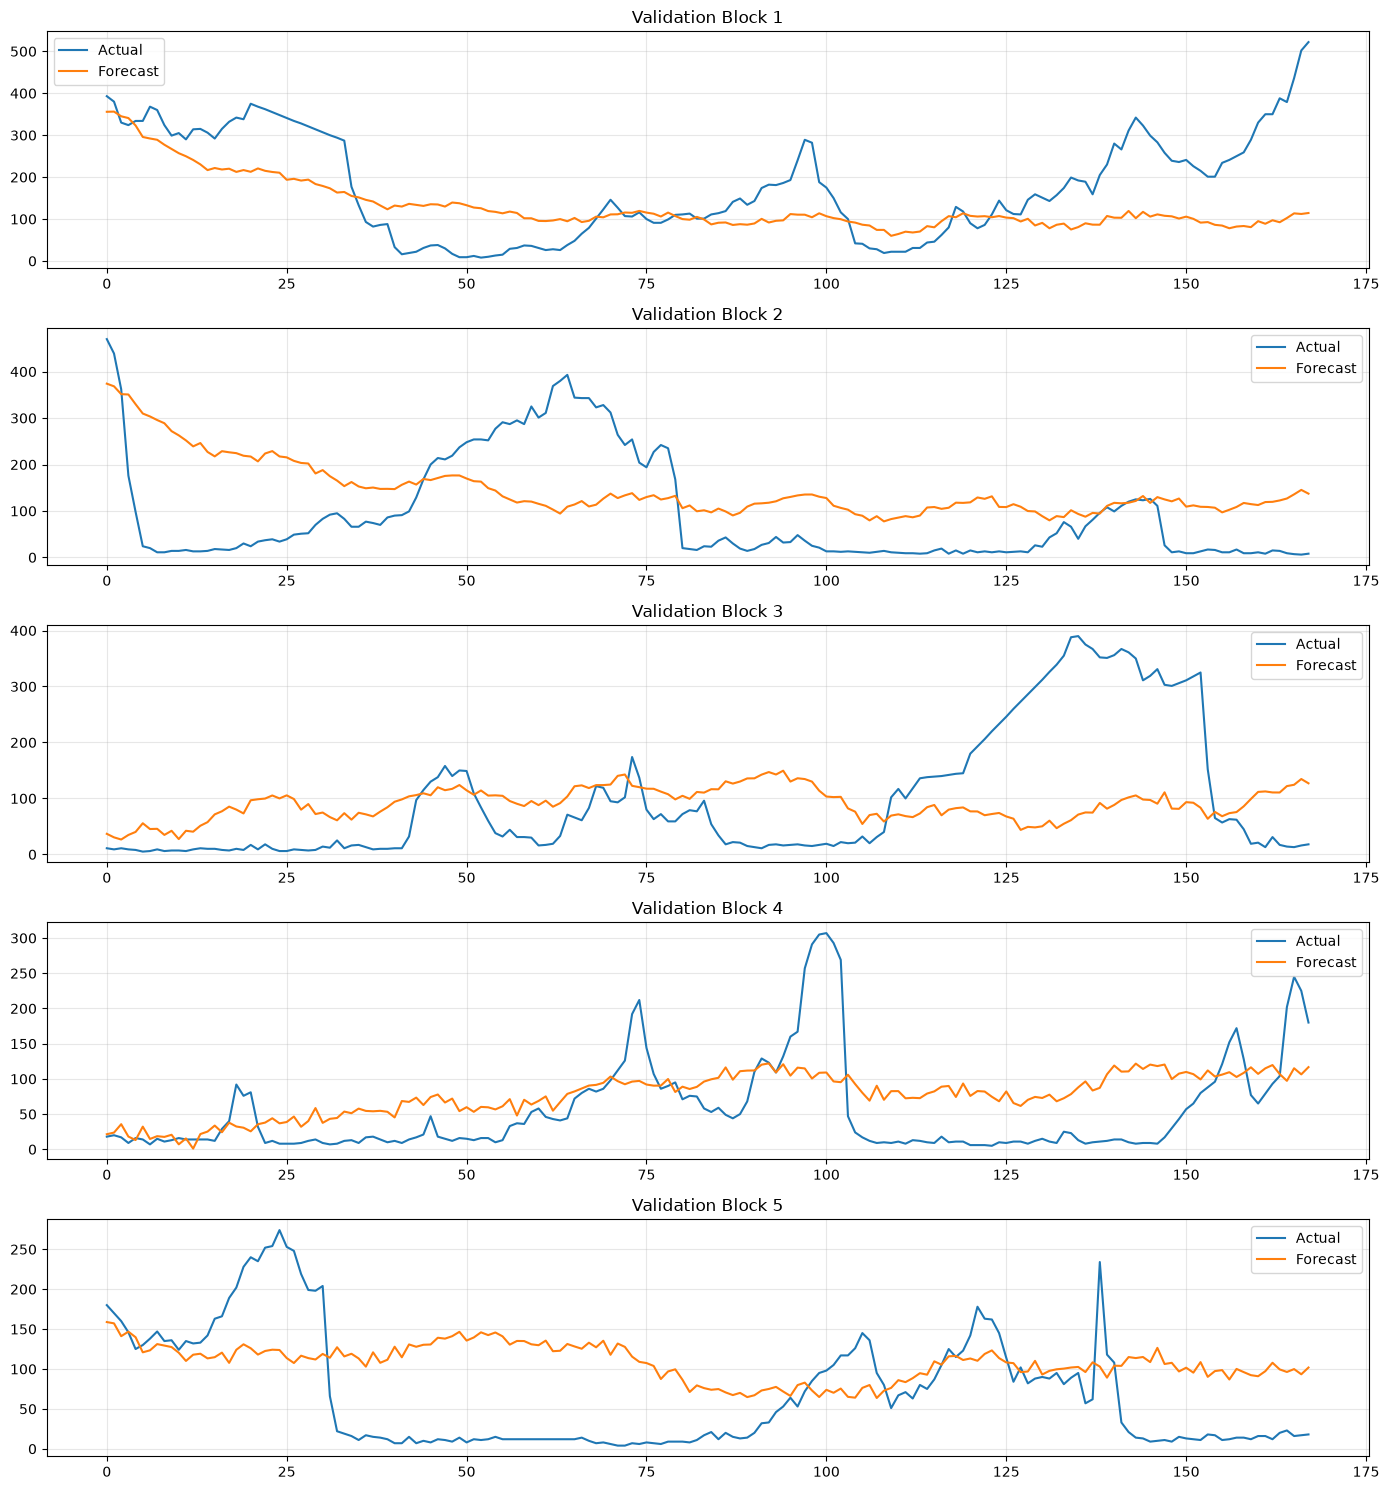

In [86]:
fig, axes = plt.subplots(
    VAL_BLOCKS,
    1,
    figsize=(14, 3 * VAL_BLOCKS),
)

if VAL_BLOCKS == 1:
    axes = [axes]

for i in range(VAL_BLOCKS):
    axes[i].plot(
        target_42[i],
        label="Actual",
    )
    axes[i].plot(
        pred_42[i],
        label="Forecast",
    )
    axes[i].set_title(
        f"Validation Block {i + 1}"
    )
    axes[i].legend()
    axes[i].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Multi-seed validation

In [87]:
seed_results = []
trained_models = {}
histories = {}
best_epochs = {}

for seed in SEEDS:
    print("\n" + "=" * 70)
    print("TRAINING SEED:", seed)
    print("=" * 70)

    model, history, best_epoch = train_model(
        seed=seed,
        epochs=EPOCHS,
    )

    metrics, predictions, targets = evaluate(
        model,
        val_loader,
        TRAIN_MEAN,
        TRAIN_STD,
    )

    seed_results.append({
        "Seed": seed,
        "RMSE": metrics["RMSE"],
        "MAE": metrics["MAE"],
        "sMAPE": metrics["sMAPE"],
        "Best Epoch": best_epoch,
    })

    trained_models[seed] = model
    histories[seed] = history
    best_epochs[seed] = best_epoch

results_df = pd.DataFrame(seed_results)
display(results_df)


TRAINING SEED: 42
Seed 42 | Epoch 01 | Loss 1.00032 | RMSE 107.8442 | MAE 90.0201 | sMAPE 99.08%
Seed 42 | Epoch 02 | Loss 0.94790 | RMSE 105.7775 | MAE 86.7623 | sMAPE 96.83%
Seed 42 | Epoch 03 | Loss 0.92809 | RMSE 107.8715 | MAE 88.3604 | sMAPE 97.13%
Seed 42 | Epoch 04 | Loss 0.91449 | RMSE 106.7384 | MAE 85.2557 | sMAPE 94.77%
Seed 42 | Epoch 05 | Loss 0.90762 | RMSE 105.8341 | MAE 82.7416 | sMAPE 92.70%
Seed 42 | Epoch 06 | Loss 0.90259 | RMSE 106.5850 | MAE 83.8985 | sMAPE 92.06%
Seed 42 | Epoch 07 | Loss 0.89597 | RMSE 108.9566 | MAE 85.0680 | sMAPE 93.21%
Seed 42 | Epoch 08 | Loss 0.89403 | RMSE 106.7419 | MAE 83.0937 | sMAPE 91.92%
Seed 42 | Epoch 09 | Loss 0.89068 | RMSE 108.8438 | MAE 84.3625 | sMAPE 92.62%
Seed 42 | Epoch 10 | Loss 0.88669 | RMSE 107.4980 | MAE 84.2281 | sMAPE 93.52%
Seed 42 | Epoch 11 | Loss 0.88802 | RMSE 106.3960 | MAE 82.6992 | sMAPE 91.42%
Seed 42 | Epoch 12 | Loss 0.88263 | RMSE 110.0699 | MAE 86.7888 | sMAPE 93.51%
Seed 42 | Epoch 13 | Loss 0.87946

,Seed,RMSE,MAE,sMAPE,Best Epoch
0,42,105.777534,86.762268,96.825317,2
1,123,104.879669,84.927956,95.560493,2
2,456,104.195946,83.429268,91.649109,6


In [88]:
summary = pd.DataFrame({
    "Metric": ["RMSE", "MAE", "sMAPE"],
    "Mean": [
        results_df["RMSE"].mean(),
        results_df["MAE"].mean(),
        results_df["sMAPE"].mean(),
    ],
    "Std": [
        results_df["RMSE"].std(),
        results_df["MAE"].std(),
        results_df["sMAPE"].std(),
    ],
})

display(summary)

FINAL_EPOCHS = max(
    1,
    int(np.median(list(best_epochs.values())))
)

print("Selected final training epochs:", FINAL_EPOCHS)

,Metric,Mean,Std
0,RMSE,104.951050,0.793207
1,MAE,85.039831,1.669314
2,sMAPE,94.678307,2.698513


Selected final training epochs: 2


# Final refit on all 43,656 known observations

Do this only after you are satisfied with the validation configuration.

In [ ]:
FULL_MEAN = float(values.mean())
FULL_STD = float(values.std())

if FULL_STD == 0:
    raise ValueError("Full-series standard deviation is zero.")

full_scaled = (
    (values - FULL_MEAN) / FULL_STD
).astype(np.float32)

full_dataset = ForecastDataset(
    full_scaled,
    context_len=CONTEXT_LEN,
    pred_len=PRED_LEN,
    stride=4,
)

full_loader = DataLoader(
    full_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
)

print("Full training windows:", len(full_dataset))
print("Full mean:", FULL_MEAN)
print("Full std:", FULL_STD)

In [ ]:
FINAL_SEED = 42
set_seed(FINAL_SEED)

final_model = make_model()

FINAL_PARAMS = sum(
    p.numel()
    for p in final_model.parameters()
    if p.requires_grad
)

optimizer = torch.optim.AdamW(
    final_model.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY,
)

criterion = nn.MSELoss()

for epoch in range(1, FINAL_EPOCHS + 1):
    final_model.train()

    running_loss = 0.0
    batches = 0

    for x, y in full_loader:
        x = x.to(DEVICE)
        y = y.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        pred = final_model(x)
        loss = criterion(pred, y)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            final_model.parameters(),
            1.0,
        )

        optimizer.step()

        running_loss += loss.item()
        batches += 1

    print(
        f"Epoch {epoch:02d}/{FINAL_EPOCHS} | "
        f"Loss: {running_loss / max(batches, 1):.5f}"
    )

print(f"Final trainable parameters: {FINAL_PARAMS:,}")

## Generate the 168-step hidden forecast

In [ ]:
test_df = pd.read_csv(TEST_PATH)

display(test_df.head())
display(test_df.tail())

assert "time_idx" in test_df.columns
assert len(test_df) == PRED_LEN, (
    f"Expected {PRED_LEN} test rows, got {len(test_df)}"
)

print("Test rows:", len(test_df))

In [ ]:
final_context = torch.tensor(
    full_scaled[-CONTEXT_LEN:],
    dtype=torch.float32,
).reshape(
    1,
    CONTEXT_LEN,
    1,
).to(DEVICE)

final_model.eval()

with torch.no_grad():
    forecast_scaled = (
        final_model(final_context)
        .cpu()
        .numpy()
        .reshape(-1)
    )

forecast = (
    forecast_scaled * FULL_STD
    + FULL_MEAN
)

assert len(forecast) == PRED_LEN

print("Predictions:", len(forecast))
print("NaNs:", np.isnan(forecast).sum())
print("Infinite:", np.isinf(forecast).sum())
print("Negative predictions:", int((forecast < 0).sum()))
print("Min:", forecast.min())
print("Max:", forecast.max())
print("Mean:", forecast.mean())

In [ ]:
history_length = min(500, len(values))

plt.figure(figsize=(15, 5))

plt.plot(
    np.arange(history_length),
    values[-history_length:],
    label="Observed",
)

plt.plot(
    np.arange(
        history_length,
        history_length + PRED_LEN,
    ),
    forecast,
    label="Forecast",
)

plt.axvline(
    history_length - 1,
    linestyle="--",
)

plt.xlabel("Relative Time")
plt.ylabel("Value")
plt.title("Final 168-Step Forecast")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
prediction_df = pd.DataFrame({
    "time_idx": test_df["time_idx"].values,
    "prediction": forecast,
})

display(prediction_df)

# Convenience copy saved locally as well.
prediction_df.to_csv(
    "task2_predictions.csv",
    index=False,
)

print("Saved task2_predictions.csv")

## Leaderboard-ready output

In [ ]:
submission_string = ", ".join(
    f"{float(x):.6f}"
    for x in forecast
)

assert len(submission_string.split(",")) == 168

print(submission_string)

In [ ]:
print("=" * 60)
print("TASK 2 SUBMISSION INFORMATION")
print("=" * 60)

print("Forecasts:", len(forecast))
print("Trainable parameters:", FINAL_PARAMS)
print("Final refit epochs:", FINAL_EPOCHS)
print("Context length:", CONTEXT_LEN)
print("Prediction length:", PRED_LEN)
print("d_model:", D_MODEL)
print("Heads:", HEADS)
print("Layers:", LAYERS)
print("Decomposition kernel:", KERNEL)
print("Model: Autoformer-style decomposition + time-delay autocorrelation")

## Next experiment: optional external variables

The assignment also requires a **with-vs-without optional external-data ablation across multiple seeds**. Do not use the hidden leaderboard as the tuning signal. Establish this target-only baseline first, then add the external variables using the same chronological validation blocks so the comparison is fair.